# Q1 — Ce qui distingue une réservation annulée d'une réservation honorée
**Auteur :** Aristote Izamo

## 1. Compréhension du problème et chargement des données

In [ ]:
# importations de bibliothèques de calcul et de visualisation
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv("../data/clean/valmont_clean.csv")

print("Shape :", df.shape)
print("Colonnes :", df.columns.tolist())
print("\nValeurs manquantes :\n", df.isna().sum()[df.isna().sum() > 0])

# identifier la variable cible (annulation) et les variables catégorielles
for col in df.columns:
    if df[col].nunique() <= 15:
        print(f"\n---{col}---")
        print(df[col].value_counts(dropna=False))

Shape : (800, 23)
Colonnes : ['reservation_id', 'hotel_id', 'segment_declare', 'nb_nuits', 'nb_personnes', 'delai_reservation_j', 'mois_sejour', 'weekend', 'canal', 'prix_nuit_eur', 'petit_dejeuner', 'nuitees_cumulees_client', 'a_annule', 'nb_personnes_manquant', 'petit_dejeuner_manquant', 'flag_anomalie', 'motif_anomalie', 'saison', 'ville', 'categorie', 'chambres', 'salles_seminaire', 'distance_gare_km']

Valeurs manquantes :
 motif_anomalie    794
dtype: int64

---segment_declare---
segment_declare
loisir      329
affaires    321
groupe      150
Name: count, dtype: int64

---nb_nuits---
nb_nuits
2      241
3      210
4      127
1      110
5       64
6       25
7       14
8        5
365      3
9        1
Name: count, dtype: int64

---mois_sejour---
mois_sejour
8     87
5     82
1     75
3     74
12    70
4     64
10    63
2     60
11    58
9     57
6     56
7     54
Name: count, dtype: int64

---weekend---
weekend
0    548
1    252
Name: count, dtype: int64

---canal---
canal
OTA    

**Interpretation**: 

Taux d'annulation (canal x segment_declare) :
 segment_declare  affaires  groupe  loisir
canal                                    
OTA                 0.145   0.365   0.369
agence              0.065   0.333   0.283
direct              0.202   0.348   0.299
entreprise          0.190   0.270   0.281


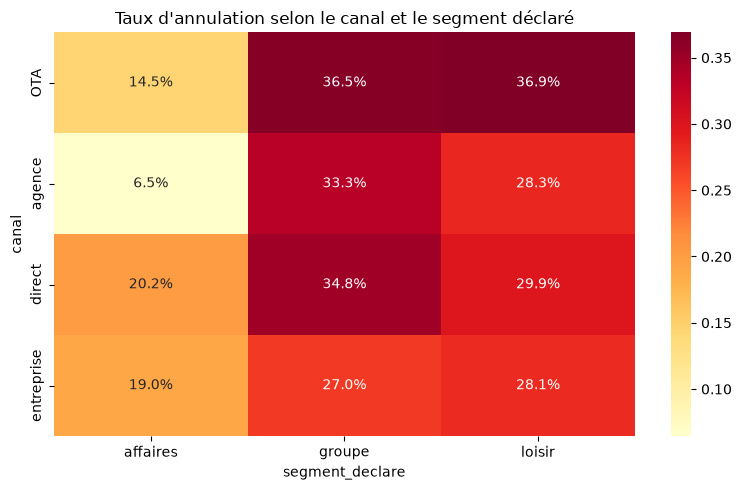

In [10]:
cible = "a_annule"

if {"canal", "segment_declare"}.issubset(df.columns):
  # Tableau croisé des taux d'annulation moyens
  pivot_annul = df.pivot_table(
      index="canal", columns="segment_declare", values=cible, aggfunc="mean"
  )
  print("Taux d'annulation (canal x segment_declare) :\n", pivot_annul.round(3))

  plt.figure(figsize=(8, 5))
  sns.heatmap(pivot_annul, annot=True, fmt=".1%", cmap="YlOrRd")
  plt.title("Taux d'annulation selon le canal et le segment déclaré")
  plt.tight_layout()
  plt.show()